
## 1. Loading the Disease Outbreak Dataset

This section loads the Global Infectious Disease Outbreaks dataset into a Pandas DataFrame.

The dataset contains information about reported infectious disease outbreaks across different countries and years.

The `read_csv()` function is used to import the CSV file, while `head(10)` displays the first ten records to provide an initial overview of the data.


In [4]:
import pandas as pd
from pathlib import Path

# Load the dataset
data_path = Path(r"c:\Users\USER\Downloads\open_data  disease_outbreaks - Data explorer.csv")
df = pd.read_csv(data_path)

# Display the first five rows
df.head(10)

,Country,Year,Type of disease,Disease
0,Afghanistan,2024,Arthropod-borne viral fevers and viral haemorr...,"Dengue, unspecified"
1,Afghanistan,2024,Provisional assignment of new diseases of unce...,"COVID-19, virus identified"
2,Afghanistan,2023,Intestinal infectious diseases,Classical cholera
3,Afghanistan,2023,Provisional assignment of new diseases of unce...,"COVID-19, virus identified"
4,Afghanistan,2022,Intestinal infectious diseases,Classical cholera
5,Afghanistan,2022,Viral infections characterized by skin and muc...,Measles
6,Afghanistan,2022,Provisional assignment of new diseases of unce...,"COVID-19, virus identified"
7,Afghanistan,2021,Provisional assignment of new diseases of unce...,"COVID-19, virus identified"
8,Afghanistan,2020,Provisional assignment of new diseases of unce...,"COVID-19, virus identified"
9,Afghanistan,2019,Arthropod-borne viral fevers and viral haemorr...,"Dengue, unspecified"



## 2. Data Quality Assessment

This section evaluates the quality and structure of the infectious disease outbreak dataset.

The assessment focuses on:
- Identifying duplicate records.
- Detecting missing values.
- Examining unique values in each variable.
- Understanding the dataset dimensions.

These checks will help identify potential data quality issues before conducting the epidemiological analysis.


In [5]:
# 1. Create a working copy
df_clean = df.copy()

# 2. Check duplicate records
print("Duplicate records:", df_clean.duplicated().sum())

# 3. Check missing values
print("\nMissing values per column:")
print(df_clean.isnull().sum())

# 4. Check unique values in important columns
for column in df_clean.columns:
    print(f"\n{column}:")
    print("Unique values:", df_clean[column].nunique())
    print(df_clean[column].dropna().unique()[:10])

# 5. Dataset dimensions
print("\nFinal dataset dimensions:", df_clean.shape)

Duplicate records: 3

Missing values per column:
Country            0
Year               0
Type of disease    0
Disease            0
dtype: int64

Country:
Unique values: 236
['Afghanistan' 'Albania' 'Algeria' 'American Samoa' 'Andorra' 'Angola'
 'Anguilla' 'Antigua and Barbuda' 'Argentina' 'Armenia']

Year:
Unique values: 29
[2024 2023 2022 2021 2020 2019 2009 2005 2003 2002]

Type of disease:
Unique values: 23
['Arthropod-borne viral fevers and viral haemorrhagic fevers'
 'Provisional assignment of new diseases of uncertain etiology or emergency use'
 'Intestinal infectious diseases'
 'Viral infections characterized by skin and mucous membrane lesions'
 'Influenza and pneumonia' 'Other bacterial diseases' 'Protozoal diseases'
 'Codes for special purposes' 'Other infectious diseases'
 'Viral infections of the central nervous system']

Disease:
Unique values: 86
['Dengue, unspecified' 'COVID-19, virus identified' 'Classical cholera'
 'Measles'
 'Influenza due to identified zoonotic or 

In [30]:
# Remove duplicate records
df_clean = df_clean.drop_duplicates().copy()

# Standardize text values
for col in ["Country", "Disease", "Type of disease"]:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

# Convert Year to numeric
df_clean["Year"] = pd.to_numeric(
    df_clean["Year"], errors="coerce"
).astype("Int64")

# Remove records without essential information
df_clean = df_clean.dropna(
    subset=["Country", "Year", "Disease"]
).reset_index(drop=True)
df_clean.to_excel(
    r"C:\Users\USER\Downloads\Global_Disease_Outbreaks_Cleaned.xlsx",
    index=False
)

print("File exported successfully!")

File exported successfully!



## 3. Dataset Overview

This section provides an overview of the dataset structure and its main characteristics.

The analysis examines:
- The total number of records and variables.
- The names of the available columns.
- The data types of each variable.

This overview helps us understand the information available for the subsequent epidemiological analysis.


In [7]:
# Dataset dimensions
print("Number of records:", df.shape[0])
print("Number of variables:", df.shape[1])

# Column names
print("\nDataset Columns:")
print(df.columns.tolist())

# Dataset information
print("\nDataset Information:")
df.info()

Number of records: 3056
Number of variables: 4

Dataset Columns:
['Country', 'Year', 'Type of disease', 'Disease']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3056 entries, 0 to 3055
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Country          3056 non-null   object
 1   Year             3056 non-null   int64 
 2   Type of disease  3056 non-null   object
 3   Disease          3056 non-null   object
dtypes: int64(1), object(3)
memory usage: 95.6+ KB



## 3. Most Frequently Reported Diseases

This analysis identifies the infectious diseases with the highest number of reported outbreak records.

A horizontal bar chart is used to compare the 15 most frequently reported diseases, highlighting the distribution of outbreak reports across different diseases.


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

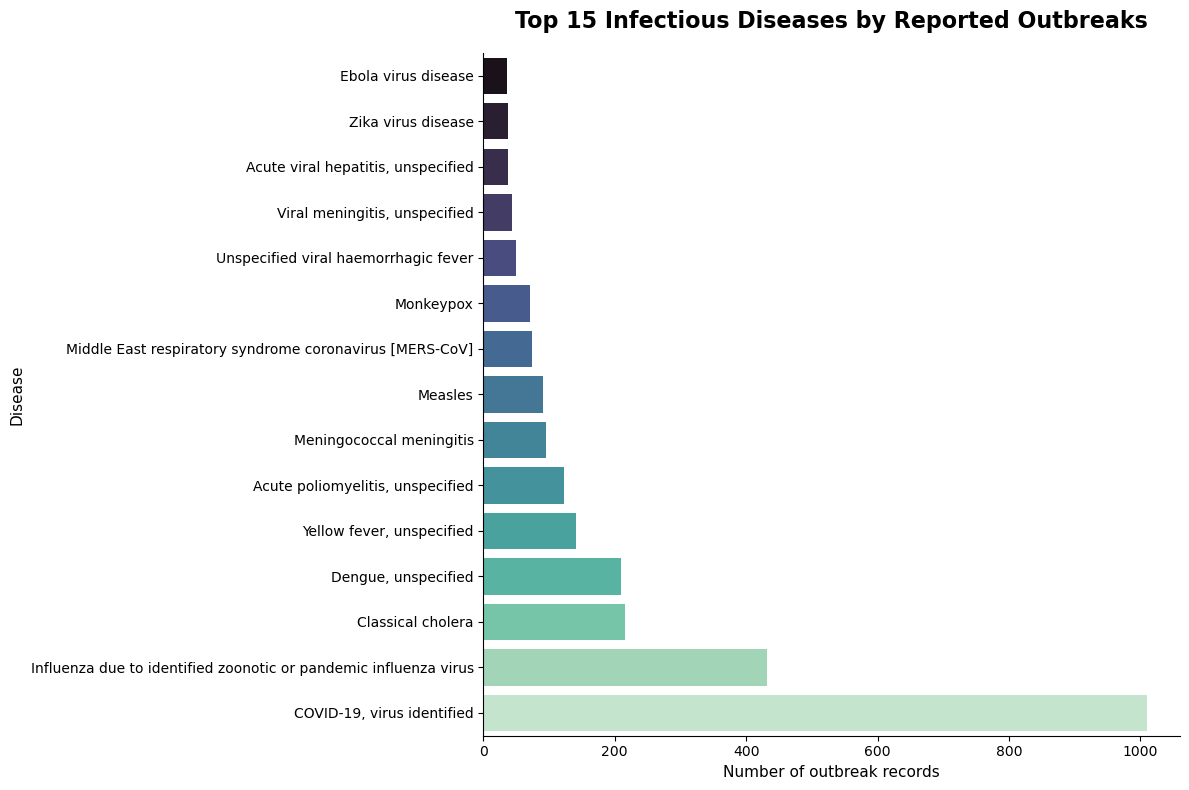

In [ ]:
# Count outbreak records by disease
disease_counts = (
    df["Disease"]
    .value_counts()
    .head(15)
    .sort_values()
)

# Create visualization
fig, ax = plt.subplots(figsize=(12, 8))

sns.barplot(
    x=disease_counts.values,
    y=disease_counts.index,
    hue=disease_counts.index,
    palette="mako",
    legend=False,
    ax=ax
)

ax.set_title(
    "Top 15 Infectious Diseases by Reported Outbreaks",
    fontsize=16,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Number of outbreak records", fontsize=11)
ax.set_ylabel("Disease", fontsize=11)

sns.despine()
plt.tight_layout()
plt.show()


## 4. Global Outbreak Trends Over Time

This section explores the temporal distribution of reported infectious disease outbreaks from 1996 onward.

A time-series visualization is used to identify periods of increased outbreak activity, fluctuations over time, and potential long-term patterns.


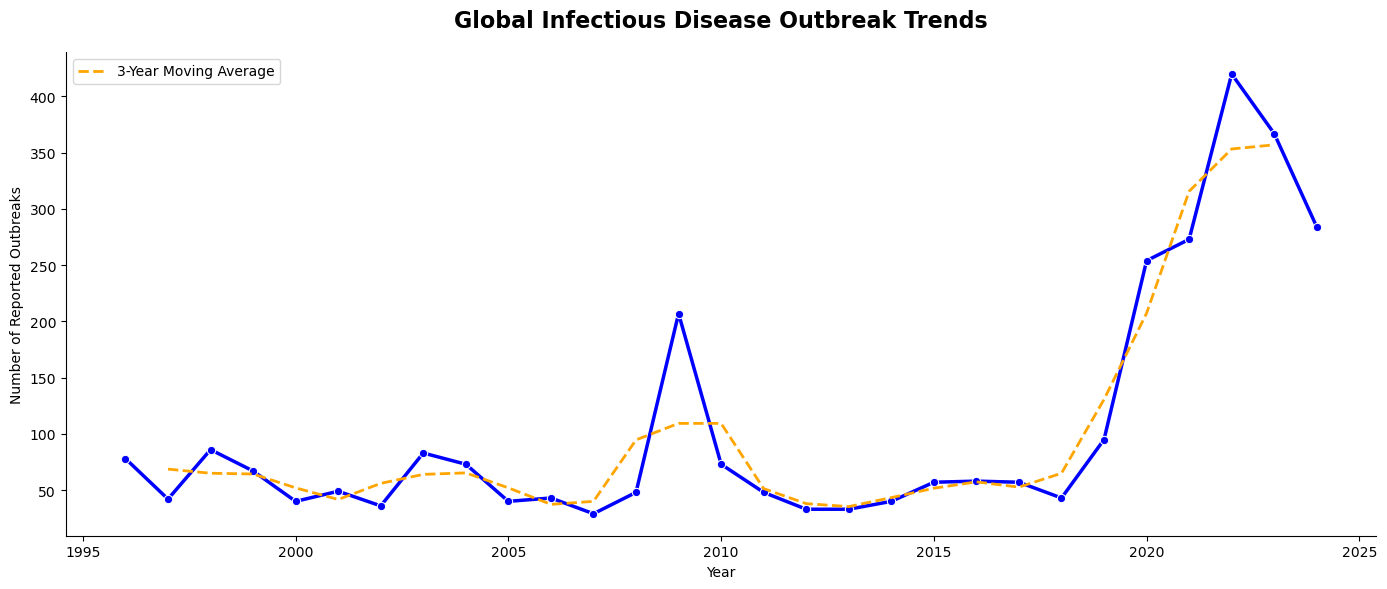

In [11]:
# Count outbreak records by year
yearly_outbreaks = (
    df.groupby("Year")
    .size()
    .reset_index(name="Number of Outbreaks")
)

# Create time-series visualization
fig, ax = plt.subplots(figsize=(14, 6))

sns.lineplot(
    data=yearly_outbreaks,
    x="Year",
    y="Number of Outbreaks",
    marker="o",
    linewidth=2.5,
    color="blue",
    ax=ax
)

# Add a rolling average
yearly_outbreaks["Moving Average"] = (
    yearly_outbreaks["Number of Outbreaks"]
    .rolling(window=3, center=True)
    .mean()
)

sns.lineplot(
    data=yearly_outbreaks,
    x="Year",
    y="Moving Average",
    color="orange",
    linewidth=2,
    linestyle="--",
    label="3-Year Moving Average",
    ax=ax
)

ax.set_title(
    "Global Infectious Disease Outbreak Trends",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Year")
ax.set_ylabel("Number of Reported Outbreaks")
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()


## 5. Geographic Distribution of Disease Outbreaks

This section examines the geographic distribution of reported infectious disease outbreaks.

It identifies the countries with the highest number of outbreak records and highlights differences in reported outbreak frequency across countries.


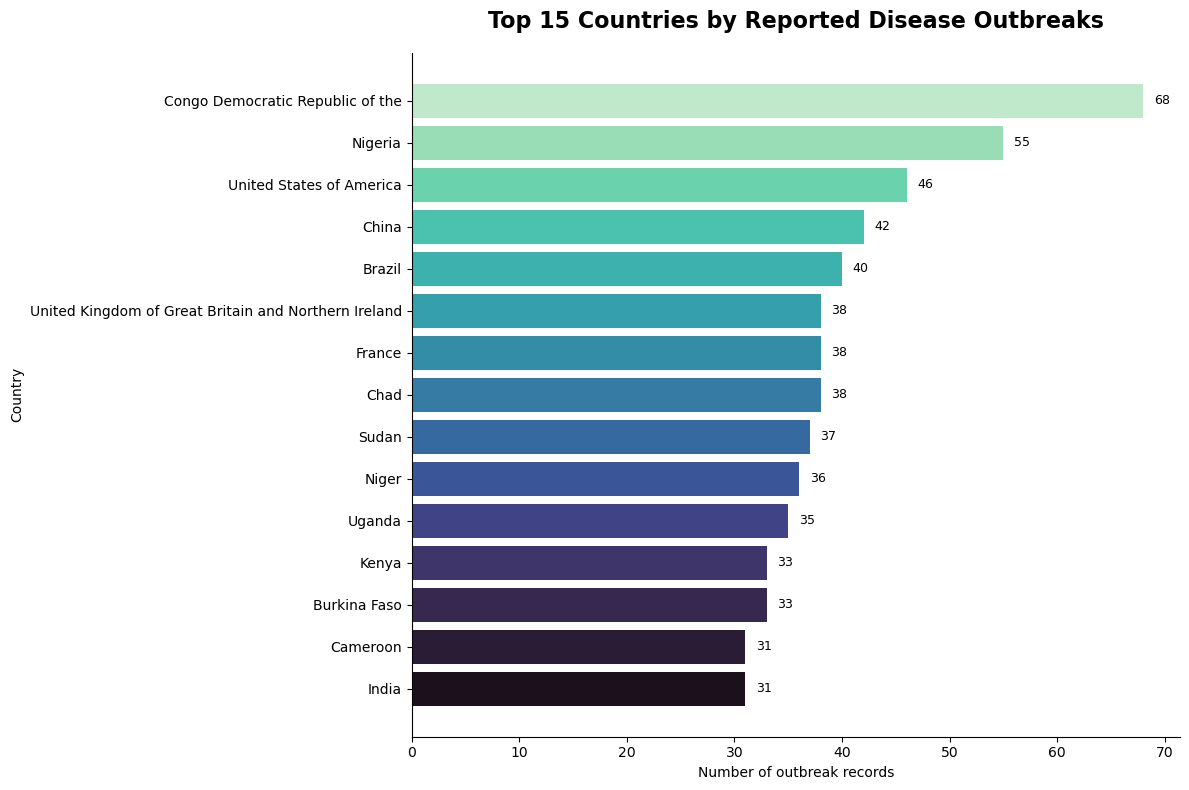

In [12]:
# Count outbreak records by country
country_counts = (
    df.groupby("Country")
    .size()
    .sort_values(ascending=False)
    .head(15)
    .sort_values()
)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    country_counts.index,
    country_counts.values,
    color=sns.color_palette("mako", len(country_counts))
)

# Add values at the end of each bar
for bar in bars:
    width = bar.get_width()
    ax.text(
        width + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width)}",
        va="center",
        fontsize=9
    )

ax.set_title(
    "Top 15 Countries by Reported Disease Outbreaks",
    fontsize=16,
    fontweight="bold",
    pad=18
)
ax.set_xlabel("Number of outbreak records")
ax.set_ylabel("Country")

sns.despine()
plt.tight_layout()
plt.show()


## 6. Distribution of Outbreaks by Disease Type

This section investigates how reported disease outbreaks are distributed across different disease categories.

The visualization compares the frequency of outbreak records by disease type, helping identify the categories that contribute most to the overall outbreak dataset.


In [18]:
# Count outbreak records by disease type
type_counts = (
    df["Type of disease"]
    .value_counts()
    .sort_values(ascending=True)
)

# Create interactive bar chart
fig = px.bar(
    x=type_counts.values,
    y=type_counts.index,
    orientation="h",
    color=type_counts.values,
    color_continuous_scale="Tealgrn",
    text=type_counts.values,
    labels={
        "x": "Number of outbreak records",
        "y": "Disease category",
        "color": "Outbreak records"
    },
    title="Global Distribution of Disease Outbreaks by Category"
)

fig.update_traces(
    textposition="outside",
    hovertemplate="<b>%{y}</b><br>Outbreak records: %{x}<extra></extra>"
)

fig.update_layout(
    title_font_size=19,
    title_x=0.5,
    template="plotly_white",
    height=600,
    showlegend=False
)

fig.show()


## 7. Disease Outbreak Patterns Across Years

This section examines how the frequency of reported infectious diseases changes over time.

A heatmap is used to visualize outbreak patterns across years and disease categories. It helps identify periods of increased reporting activity and compare the temporal distribution of different diseases.


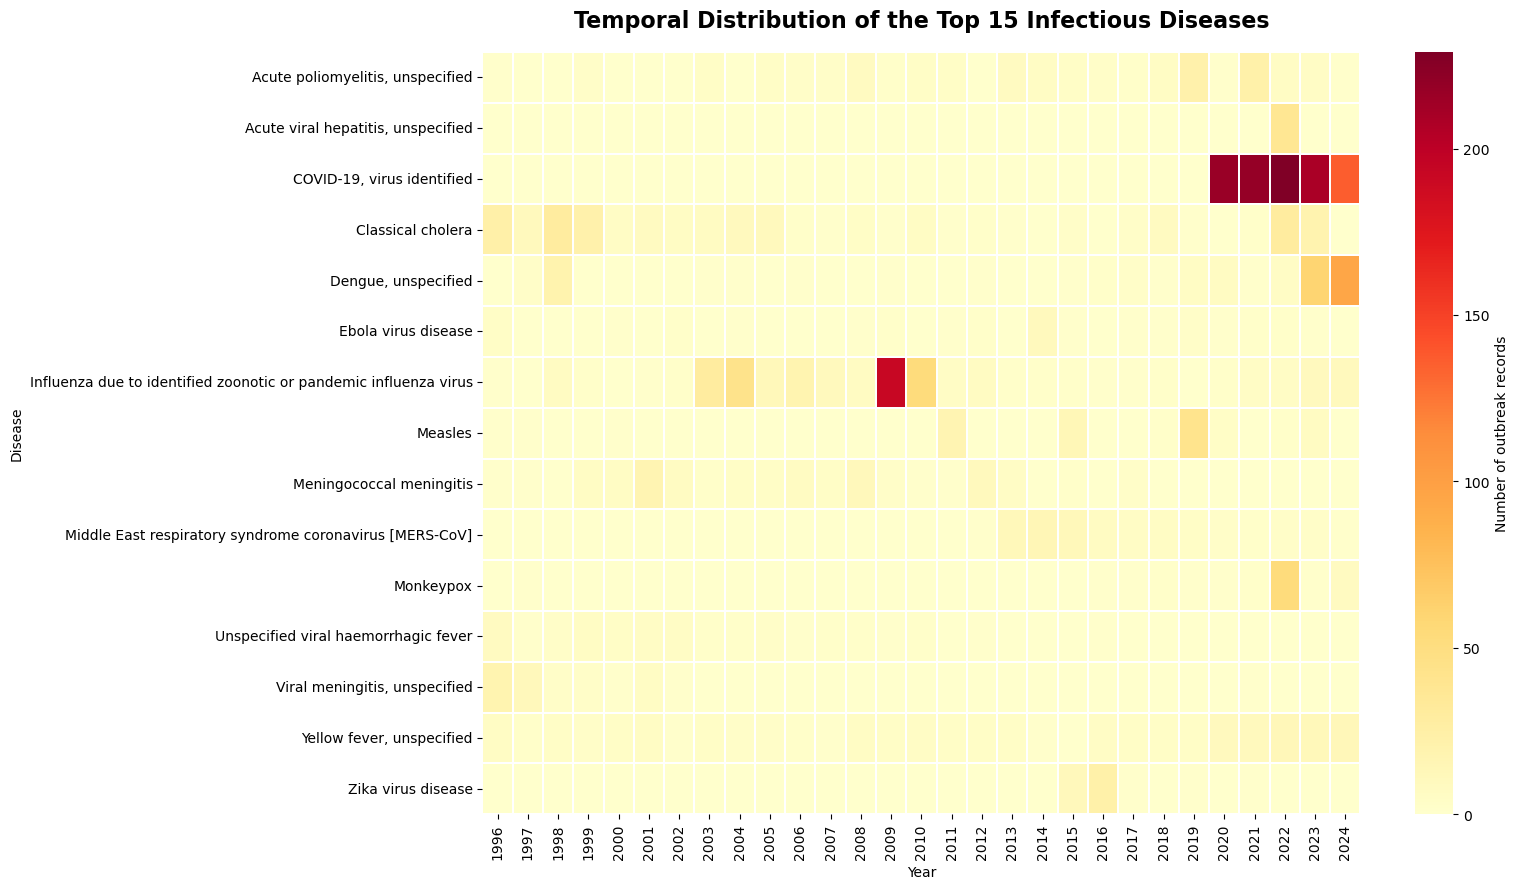

In [19]:
# Select the 15 most frequently reported diseases
top_diseases = df["Disease"].value_counts().head(15).index

# Filter dataset
heatmap_data = df[df["Disease"].isin(top_diseases)]

# Create disease-year frequency table
disease_year = pd.crosstab(
    heatmap_data["Disease"],
    heatmap_data["Year"]
)

# Create heatmap
plt.figure(figsize=(16, 9))

sns.heatmap(
    disease_year,
    cmap="YlOrRd",
    linewidths=0.3,
    linecolor="white",
    cbar_kws={"label": "Number of outbreak records"}
)

plt.title(
    "Temporal Distribution of the Top 15 Infectious Diseases",
    fontsize=16,
    fontweight="bold",
    pad=18
)

plt.xlabel("Year")
plt.ylabel("Disease")
plt.tight_layout()
plt.show()


## 8. lobal Geographic Distribution of Disease Outbreaks

This section visualizes the geographic distribution of reported infectious disease outbreaks across the world.

An interactive choropleth map is used to compare outbreak reporting frequencies between countries. Darker colors represent higher numbers of reported outbreak records.

The map provides a global perspective on the geographic distribution of infectious disease outbreak reports.


In [20]:
# Aggregate outbreak records by country
map_data = (
    df.groupby("Country")
    .size()
    .reset_index(name="Number of Outbreaks")
)

# Create interactive world map
fig = px.choropleth(
    map_data,
    locations="Country",
    locationmode="country names",
    color="Number of Outbreaks",
    hover_name="Country",
    color_continuous_scale="YlOrRd",
    title="Global Distribution of Reported Disease Outbreaks",
    projection="natural earth"
)

fig.update_layout(
    title_x=0.5,
    title_font_size=20,
    template="plotly_white",
    height=650,
    margin={"r": 0, "t": 60, "l": 0, "b": 0}
)

fig.show()


## 9. Disease Distribution Across Countries

This analysis examines the distribution of different infectious diseases across countries.

It identifies countries with the greatest diversity of reported diseases, providing insight into the variety of outbreak records documented in different geographical locations.


In [21]:
country_diversity = (
    df.groupby("Country")["Disease"]
    .nunique()
    .sort_values(ascending=False)
    .head(15)
)

display(country_diversity.to_frame("Number of Unique Diseases"))

,Number of Unique Diseases
Country,
United States of America,27
France,24
United Kingdom of Great Britain and Northern Ireland,21
Sudan,18
Brazil,17
Spain,16
India,16
China,16
Congo Democratic Republic of the,15



## 10. Yearly Outbreak Intensity

This analysis examines the annual intensity of reported infectious disease outbreaks.

It identifies the years with the highest and lowest numbers of reported outbreak records and measures how outbreak reporting activity changes from one year to another.


In [22]:
# Calculate annual outbreak frequency
yearly_analysis = (
    df.groupby("Year")
    .size()
    .reset_index(name="Outbreaks")
)

# Calculate year-over-year percentage change
yearly_analysis["Annual Change (%)"] = (
    yearly_analysis["Outbreaks"]
    .pct_change()
    .mul(100)
    .round(2)
)

# Display highest outbreak years
print("Top 10 Years by Reported Outbreaks:")
display(
    yearly_analysis.nlargest(10, "Outbreaks")
    .reset_index(drop=True)
)

# Display annual changes
print("\nAnnual Changes in Reported Outbreaks:")
display(yearly_analysis.tail(10))

Top 10 Years by Reported Outbreaks:


,Year,Outbreaks,Annual Change (%)
0,2022,420,53.85
1,2023,367,-12.62
2,2024,284,-22.62
3,2021,273,7.48
4,2020,254,167.37
5,2009,207,331.25
6,2019,95,120.93
7,1998,86,104.76
8,2003,83,130.56
9,1996,78,NaN



Annual Changes in Reported Outbreaks:


,Year,Outbreaks,Annual Change (%)
19,2015,57,42.50
20,2016,58,1.75
21,2017,57,-1.72
22,2018,43,-24.56
23,2019,95,120.93
24,2020,254,167.37
25,2021,273,7.48
26,2022,420,53.85
27,2023,367,-12.62
28,2024,284,-22.62



## 11. Relationship Between Disease Diversity and Outbreak Frequency

This analysis compares the number of reported outbreak records with the diversity of infectious diseases across countries.

It explores whether countries with more reported outbreak records also tend to have a greater variety of documented diseases.


In [23]:
# Calculate outbreak frequency and disease diversity by country
country_analysis = (
    df.groupby("Country")
    .agg(
        Total_Outbreaks=("Disease", "count"),
        Unique_Diseases=("Disease", "nunique")
    )
    .reset_index()
)

# Calculate Pearson correlation
correlation = country_analysis[
    ["Total_Outbreaks", "Unique_Diseases"]
].corr(method="pearson")

print("Correlation Matrix:")
display(correlation)

# Display the top countries
display(
    country_analysis
    .sort_values("Total_Outbreaks", ascending=False)
    .head(15)
)

Correlation Matrix:


,Total_Outbreaks,Unique_Diseases
Total_Outbreaks,1.000000,0.887244
Unique_Diseases,0.887244,1.000000


,Country,Total_Outbreaks,Unique_Diseases
45,Congo Democratic Republic of the,68,15
154,Nigeria,55,14
224,United States of America,46,27
41,China,42,16
28,Brazil,40,17
39,Chad,38,11
70,France,38,24
223,United Kingdom of Great Britain and Northern I...,38,21
202,Sudan,37,18
153,Niger,36,11



## 12. Geographical Spread of Infectious Diseases

This analysis identifies infectious diseases reported across the largest number of countries.

It helps distinguish diseases with a wide geographical distribution from those documented in a more limited number of countries.



## 13. Detection of Unusual Outbreak Patterns

This analysis identifies years with unusually high numbers of reported infectious disease outbreaks.

The Interquartile Range (IQR) method is used to detect statistical outliers in annual outbreak counts.

These unusual observations may indicate periods of increased outbreak reporting activity and deserve further investigation.


In [25]:
# Calculate annual outbreak counts
annual_counts = df.groupby("Year").size()

# Calculate IQR boundaries
Q1 = annual_counts.quantile(0.25)
Q3 = annual_counts.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify unusual years
unusual_years = annual_counts[
    (annual_counts < lower_bound) |
    (annual_counts > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nYears with Unusual Outbreak Counts:")
display(
    unusual_years
    .reset_index()
    .rename(columns={"Year": "Year", 0: "Outbreak Records"})
)

Lower Bound: -24.0
Upper Bound: 152.0

Years with Unusual Outbreak Counts:


,Year,Outbreak Records
0,2009,207
1,2020,254
2,2021,273
3,2022,420
4,2023,367
5,2024,284



## 14. Statistical Trend Analysis

This section evaluates whether the number of reported infectious disease outbreaks has followed an increasing or decreasing trend over time.

Spearman's rank correlation is used to assess the direction and strength of the relationship between calendar year and annual outbreak frequency.

The analysis provides statistical evidence of a possible temporal trend without implying causation.


In [26]:
from scipy.stats import spearmanr

# Calculate annual outbreak frequency
annual_trend = df.groupby("Year").size().reset_index(name="Outbreaks")

# Perform Spearman correlation
correlation, p_value = spearmanr(
    annual_trend["Year"],
    annual_trend["Outbreaks"]
)

print("SPEARMAN TREND ANALYSIS")
print("-----------------------")
print(f"Correlation coefficient: {correlation:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("The temporal trend is statistically significant.")
else:
    print("No statistically significant monotonic trend was detected.")

if correlation > 0:
    print("Direction: Increasing trend.")
elif correlation < 0:
    print("Direction: Decreasing trend.")
else:
    print("Direction: No monotonic trend.")

SPEARMAN TREND ANALYSIS
-----------------------
Correlation coefficient: 0.3980
P-value: 0.0325
The temporal trend is statistically significant.
Direction: Increasing trend.



## 15. Key Findings and Epidemiological Interpretation

This section summarizes the main findings obtained from the exploratory, geographical, and statistical analyses.

The objective is to translate the analytical results into meaningful public health insights while recognizing the limitations of the dataset.


In [27]:
# Generate key analytical findings

total_records = len(df)
total_countries = df["Country"].nunique()
total_diseases = df["Disease"].nunique()

first_year = df["Year"].min()
last_year = df["Year"].max()

top_disease = df["Disease"].value_counts().idxmax()
top_country = df["Country"].value_counts().idxmax()

peak_year = df["Year"].value_counts().idxmax()
peak_count = df["Year"].value_counts().max()

print("GLOBAL INFECTIOUS DISEASE OUTBREAKS: KEY FINDINGS")
print("=" * 55)

print(f"Total outbreak records: {total_records:,}")
print(f"Countries and territories: {total_countries}")
print(f"Distinct diseases: {total_diseases}")
print(f"Study period: {first_year}–{last_year}")

print(f"\nMost frequently reported disease: {top_disease}")
print(f"Country with most outbreak records: {top_country}")
print(f"Year with most outbreak records: {peak_year} ({peak_count})")

GLOBAL INFECTIOUS DISEASE OUTBREAKS: KEY FINDINGS
Total outbreak records: 3,056
Countries and territories: 236
Distinct diseases: 86
Study period: 1996–2024

Most frequently reported disease: COVID-19, virus identified
Country with most outbreak records: Congo Democratic Republic of the
Year with most outbreak records: 2022 (420)



## 16. Limitations of the Study

Despite providing valuable information on the global distribution of infectious disease outbreaks, this dataset has several limitations.

- The dataset records reported outbreaks rather than individual patient-level observations.
- Differences in disease surveillance and reporting capacity may affect comparisons between countries.
- The number of reported outbreaks does not directly measure disease incidence or population-level infection risk.
- Missing or incomplete records may affect the interpretation of certain results.
- Temporal patterns in reported outbreaks may reflect changes in surveillance practices rather than actual changes in disease occurrence.

These limitations should be considered when interpreting the findings and drawing public health conclusions.



## 17. Public Health Implications

The findings of this analysis can contribute to a better understanding of global infectious disease outbreak reporting patterns.

Identifying frequently reported diseases, geographical distributions, and unusual temporal patterns can help inform public health surveillance priorities.

However, outbreak counts should be interpreted alongside population data, surveillance coverage, and additional epidemiological indicators before informing public health decisions.



## 18. Conclusion

This project explored global infectious disease outbreak reporting patterns using historical data from multiple countries and territories.

Through data cleaning, exploratory data analysis, statistical examination, and interactive visualization, the study identified important patterns in disease distribution, geographical reporting, and temporal activity.

The findings demonstrate how Python-based data analysis can support the exploration of public health surveillance data and provide insights that may guide further epidemiological research.

Nevertheless, reported outbreak counts should not be interpreted as direct measures of disease incidence or individual infection risk.

Future research could integrate population statistics, healthcare surveillance indicators, and additional epidemiological datasets to develop a more comprehensive understanding of global infectious disease patterns.


In [32]:
from pathlib import Path

# Set the Downloads folder
output_folder = Path.home() / "Downloads"
output_folder.mkdir(parents=True, exist_ok=True)

# Export all open Matplotlib charts
for i, fig_num in enumerate(plt.get_fignums(), start=1):
    fig = plt.figure(fig_num)
    fig.savefig(
        output_folder / f"visualization_{i}.png",
        dpi=300,
        bbox_inches="tight"
    )

print(f"Visualizations saved in: {output_folder}")

Visualizations saved in: C:\Users\USER\Downloads


In [33]:
from pathlib import Path

# Exact path to your project folder
project_folder = Path(r"C:\Users\USER\Documents\Disease-Outbreak-Investigation")

# Target the Visualizations folder inside this project
output_folder = project_folder / "Visualizations"
output_folder.mkdir(parents=True, exist_ok=True)

# Export all open Matplotlib charts
for i, fig_num in enumerate(plt.get_fignums(), start=1):
    fig = plt.figure(fig_num)
    fig.savefig(
        output_folder / f"visualization_{i}.png",
        dpi=300,
        bbox_inches="tight"
    )

print("Saved in:", output_folder.resolve())

Saved in: C:\Users\USER\Documents\Disease-Outbreak-Investigation\Visualizations


In [34]:
from pathlib import Path
import matplotlib.pyplot as plt

# Directly access the Windows Downloads folder
output_folder = Path.home() / "Downloads"

# Export all open Matplotlib visualizations
for i, fig_num in enumerate(plt.get_fignums(), start=1):
    fig = plt.figure(fig_num)
    fig.savefig(
        output_folder / f"Disease_Outbreak_Visualization_{i}.png",
        dpi=300,
        bbox_inches="tight"
    )

print("Saved files:")
for file in output_folder.glob("Disease_Outbreak_Visualization_*.png"):
    print(file)

Saved files:


In [35]:
from pathlib import Path
import matplotlib.pyplot as plt

output_folder = Path.home() / "Downloads"

for i, fig_num in enumerate(plt.get_fignums(), start=1):
    fig = plt.figure(fig_num)
    path = output_folder / f"Disease_Outbreak_Visualization_{i}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved:", path)